In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

import warnings
warnings.simplefilter("ignore")

# Comparing Two Samples: A/B Testing

In [2]:
births = Table.read_table('baby.csv')
smoking_and_birthweight = births.select('Maternal Smoker', 'Birth Weight')
smoking_and_birthweight.show(6)

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136
False,138


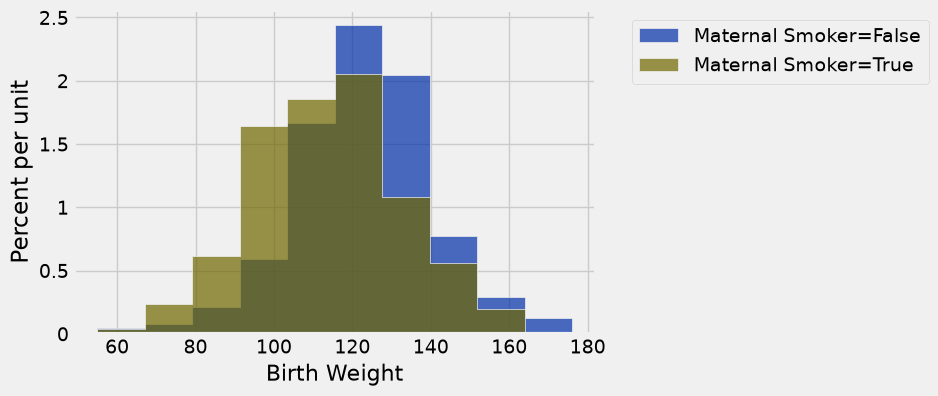

In [3]:
smoking_and_birthweight.hist('Birth Weight', group='Maternal Smoker')

In [4]:
means_table = smoking_and_birthweight.group('Maternal Smoker', np.average)
means_table

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


In [76]:
means_arr = means_table.column('Birth Weight average')
observed_difference = means_arr.item(0) - means_arr.item(1)
observed_difference

9.266142572024918

Null hypothesis: In the population, the distribution of birth weights of babies is the same for mothers who don’t smoke as for mothers who do. The difference in the sample is due to chance.

Alternative hypothesis: In the population, the babies of the mothers who smoke have a lower birth weight, on average, than the babies of the non-smokers.

# Review: Exploring Null Hypothesis with One Sample

Step 1. Write a function to simulate one occurrence of the test statistic.

Step 2. Collect many simulated instances of the test statistic (for loop and np.append).

Step 3. Load outcomes into a table (Table().with_column)

Step 4. Visualize the outcomes with a histogram (hist)

Step 5. Calculate the p-value of the observed statistic (np.count_nonzero).

# New: Exploring Null Hypothesis with Two Samples

Step 1. Write a function to simulate one occurrence of the test statistic WHICH COMPARES THE TWO SAMPLES.

Step 2. Collect many simulated instances of the test statistic BY PERMUTING CATEGORY LABELS OF THE DATA SET TO GENERATE VARIETY (sample without replacement to permute, for loop, and np.append).

Step 3. Load outcomes into a table (Table().with_column)

Step 4. Visualize the outcomes with a histogram (hist)

Step 5. Calculate the p-value of the observed statistic (np.count_nonzero).

# Step 1: Function for Test Statistic

### Shuffling labels example

In [14]:
staff = Table().with_columns(
    'Names', make_array('Jim', 'Pam', 'Dwight', 'Michael'),
    'Ages', make_array(29, 28, 34, 41)
)
staff

Names,Ages
Jim,29
Pam,28
Dwight,34
Michael,41


In [20]:
# Sampling without replacement means the same row cannot be selected twice.
# Sampling without providing a number of rows will produce a table with the same number of rows as the original.
# This example therefore produces a random permutation (shuffling) of the original table.
shuffled_staff = staff.sample(with_replacement = False)
shuffled_staff

Names,Ages
Michael,41
Jim,29
Pam,28
Dwight,34


In [21]:
# You can now put the names from the original table onto the shuffled table, which results in shuffling just the ages.
original_names = staff.column('Names')
shuffled_staff = shuffled_staff.with_column('Names', original_names)
shuffled_staff

Names,Ages
Jim,41
Pam,29
Dwight,28
Michael,34


Write a function called difference_of_means. It permutes the True/False labels of the Smoking column, calculates the average of each group, then returns the difference of the two means.

In [67]:
def difference_of_means ():
    shuffled_smokers = smoking_and_birthweight.sample(with_replacement = False)
    origional_maternal_smokers = smoking_and_birthweight.column('Maternal Smoker')
    shuffled_smokers = shuffled_smokers.with_column('Maternal Smoker', origional_maternal_smokers)
    grouped_average = shuffled_smokers.group('Maternal Smoker', np.average)
    grouped_average_array = grouped_average.column('Birth Weight average')
    diff = grouped_average_array.item(0) - grouped_average_array.item(1)
    return diff


# Step 2: Iteration

In [80]:
diffs_arr = make_array()

for _ in np.arange(1000):
    diff_of_means = difference_of_means()
    diffs_arr = np.append(diffs_arr, diff_of_means)

diffs_arr

array([  1.02773436e+00,  -3.01813611e+00,  -2.24902723e+00,
        -3.67393391e-01,   1.65017597e+00,   1.58462453e-01,
         1.22689946e-01,   5.37651020e-01,   4.87569511e-01,
        -3.73716349e+00,   8.70335329e-01,  -2.40284900e+00,
        -4.10320399e-01,  -7.00077700e-01,  -1.45603851e-01,
         3.62365739e-01,   3.80251992e-01,   1.81115225e+00,
        -4.63979158e-01,  -1.43699133e+00,   6.19927785e-01,
        -1.29390131e+00,  -3.55472371e+00,   1.33180066e+00,
         6.55700291e-01,   3.23015982e-01,   7.73749562e-01,
         1.13147463e+00,  -3.17311882e-01,  -5.96337432e-01,
        -5.85605680e-01,   1.90058351e+00,  -2.20726115e-01,
        -1.58365861e+00,  -1.06495726e+00,   1.36399592e+00,
         1.37830492e+00,   9.81230099e-01,   2.47893718e-01,
        -6.89345948e-01,   1.67521672e+00,  -5.35524171e-01,
         7.55863309e-01,   2.25269284e-02,  -4.71133659e-01,
        -6.33270869e-02,   8.81067081e-01,   2.96814297e-02,
        -7.14386703e-01,

# Step 3 and 4: Create a Table and Visualize the Data

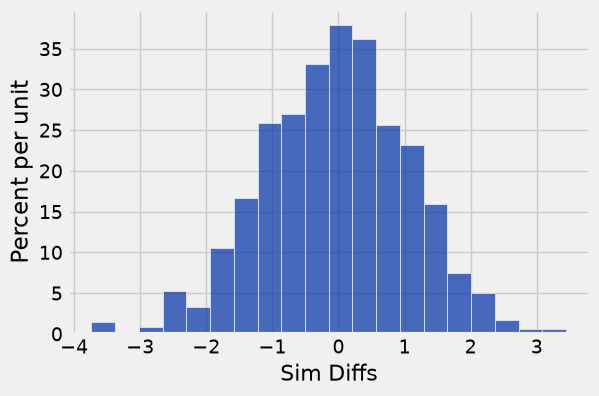

In [81]:
diff_tbl = Table().with_column('Sim Diffs', diffs_arr)
diff_tbl.hist(bins=20)

# Step 5: Calculate the p-value

Calculate the percent of all simulated differences that favor the alternative hypothesis.

In [82]:
observed_difference

9.266142572024918

In [90]:
num_alt = np.count_nonzero(diffs_arr >= observed_difference)
num_total = len(diffs_arr)
p_value = num_alt / num_total
p_value

0.0